# SkillMap — kỹ năng tuyển dụng Data / AI

Dữ liệu gốc là `topcv-skillmap-processed.csv` (TopCV, thu ngày 11/10/2026). Mình đã đưa 172 tin vào SQLite, bảng `jobs`, file `topcv_skillmap.db`. Bản SQL text cùng nội dung nằm ở `topcv_skillmap.sql`.

Notebook này chỉ đọc database. Việc cần làm: lọc tin hợp với sinh viên (3 nghề, kinh nghiệm thấp), tách kỹ năng bằng từ khóa, đếm tần suất, rồi thử một ví dụ skill gap.

Phần mô tả trong bảng là cụm từ đã trích, không phải toàn văn tin tuyển dụng.

## 1. Kết nối database và xem qua

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.family"] = "Segoe UI"
plt.rcParams["axes.unicode_minus"] = False


def find_database():
    name = "topcv_skillmap.db"
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        matches = list(kaggle_input.rglob(name))
        if matches:
            return matches[0]
    for path in [Path(name), Path("data") / name]:
        if path.exists():
            return path
    raise FileNotFoundError("Không thấy " + name)


db_path = find_database()
output_dir = Path("/kaggle/working/outputs") if Path("/kaggle").exists() else Path("outputs")
output_dir.mkdir(exist_ok=True)

conn = sqlite3.connect(db_path)
print("Database:", db_path)

overview = pd.read_sql(
    """
    SELECT role, COUNT(*) AS job_count
    FROM jobs
    GROUP BY role
    ORDER BY job_count DESC
    """,
    conn,
)
print("Tổng số tin:", int(overview["job_count"].sum()))
overview

Database: topcv_skillmap.db
Tổng số tin: 172


,role,job_count
0,ai_ml_engineer,49
1,data_analyst,49
2,other,47
3,data_engineer,27


In [2]:
missing_values = pd.read_sql(
    """
    SELECT 'role_note' AS column_name, SUM(role_note = '') AS missing_count FROM jobs
    UNION ALL
    SELECT 'date_posted', SUM(date_posted = '') FROM jobs
    """,
    conn,
)
duplicate_keys = pd.read_sql(
    """
    SELECT COUNT(*) AS duplicate_keys
    FROM (
        SELECT source, source_job_id
        FROM jobs
        GROUP BY source, source_job_id
        HAVING COUNT(*) > 1
    )
    """,
    conn,
)
print(missing_values.to_string(index=False))
print("Số khóa source + source_job_id bị trùng:", int(duplicate_keys.loc[0, "duplicate_keys"]))

jobs = pd.read_sql(
    """
    SELECT
        source_job_id,
        title_raw,
        company_raw,
        location_raw,
        experience_raw,
        job_description_raw,
        candidate_requirements_raw,
        role
    FROM jobs
    """,
    conn,
)
jobs.head(3)

column_name  missing_count
  role_note            144
date_posted             87
Số khóa source + source_job_id bị trùng: 0


,source_job_id,title_raw,company_raw,location_raw,experience_raw,job_description_raw,candidate_requirements_raw,role
0,1637186,Kỹ Sư Trí Tuệ Nhân Tạo - AI - VTNet,Tổng Công ty Mạng lưới Viettel – Chi nhánh Tập...,Hà Nội,1 năm,phát triển sản phẩm nội bộ; Chatbot; CV (Compu...,1 năm kinh nghiệm vị trí tương đương; tốt nghi...,ai_ml_engineer
1,2125555,Kỹ Sư Giải Pháp AI Camera & Smart Solutions,CÔNG TY CỔ PHẦN VIỄN THÔNG CÔNG NGHỆ TTP GROUP,Hồ Chí Minh,2 năm,phân tích yêu cầu khách hàng; khảo sát hạ tầng...,tốt nghiệp Đại học CNTT/Điện tử Viễn thông/Tự ...,ai_ml_engineer
2,2136061,AI Engineer,Công ty Cổ phần Tập đoàn TDI,Hà Nội,1 năm,"Xây dựng, triển khai sản phẩm/giải pháp AI Age...",Tốt nghiệp ĐH Bách Khoa Hà Nội/FPT/ĐH Công Ngh...,ai_ml_engineer


## 2. Lọc tin đưa vào phân tích

Chỉ giữ Data Analyst, Data Engineer, AI/ML Engineer, làm ở Việt Nam, kinh nghiệm trong cột `experience_raw` từ 0 đến 2 năm. «Không yêu cầu» và «dưới 1 năm» tính là 0.

Sau khi đọc tiêu đề, bỏ thêm tin Senior, Lead, Manager, Middle, All level, và vài tin lệch nghề (kế toán, SAP, fullstack, presale AI camera, business development, business analyst không phải data analyst).

In [3]:
def parse_years(text):
    text = str(text).lower()
    if "không yêu cầu" in text or "dưới 1" in text:
        return 0
    if "trên 5" in text:
        return 6
    numbers = [int(value) for value in re.findall(r"\d+", text)]
    if not numbers:
        return None
    # "2-3 năm" lấy 3, cho khỏi lọt tin yêu cầu trên 2 năm
    return max(numbers)


jobs["years"] = jobs["experience_raw"].apply(parse_years)
jobs["title"] = jobs["title_raw"].str.strip()
jobs["description"] = (
    jobs["job_description_raw"].str.strip() + " " + jobs["candidate_requirements_raw"].str.strip()
).str.strip()

is_target_role = jobs["role"].isin(["data_analyst", "data_engineer", "ai_ml_engineer"])
is_senior_title = jobs["title"].str.contains(
    r"\b(?:senior|lead|leader|manager|head)\b|trưởng nhóm|trưởng phòng|giám đốc|middle|all level",
    case=False,
    regex=True,
)
is_foreign = jobs["location_raw"].str.contains(
    r"nhật bản|japan|singapore|hàn quốc|\bkorea\b|thailand|\busa\b",
    case=False,
    regex=True,
)
is_off_role = jobs["title"].str.contains(
    r"kế toán|fullstack|\bsap\b|giải pháp ai camera|business development",
    case=False,
    regex=True,
)
is_business_analyst = jobs["title"].str.contains("business analyst", case=False, regex=False) & ~jobs["title"].str.contains(
    "data analyst", case=False, regex=False
)

print("Bỏ vì cấp bậc trong tiêu đề:", int((is_target_role & is_senior_title).sum()))
print("Bỏ vì địa điểm nước ngoài:", int((is_target_role & is_foreign).sum()))
print("Bỏ vì tiêu đề lệch nghề:", int((is_target_role & (is_off_role | is_business_analyst)).sum()))
print("Tin lệch nghề / cấp bậc:")
dropped = jobs[is_target_role & (is_senior_title | is_off_role | is_business_analyst)]
print(dropped[["source_job_id", "title", "role", "experience_raw"]].to_string(index=False))

filtered_jobs = jobs[
    is_target_role
    & ~is_senior_title
    & ~is_foreign
    & ~is_off_role
    & ~is_business_analyst
    & jobs["years"].notna()
    & (jobs["years"] <= 2)
].copy()
print("\nTin ban đầu:", len(jobs), "| Tin đem phân tích:", len(filtered_jobs))
print(filtered_jobs["role"].value_counts())

Bỏ vì cấp bậc trong tiêu đề: 40
Bỏ vì địa điểm nước ngoài: 0
Bỏ vì tiêu đề lệch nghề: 8
Tin lệch nghề / cấp bậc:
source_job_id                                                                                                   title           role                                 experience_raw
      2125555                                                             Kỹ Sư Giải Pháp AI Camera & Smart Solutions ai_ml_engineer                                          2 năm
      2240008                                                                     Intern AI-Driven Fullstack Engineer ai_ml_engineer                                  Không yêu cầu
      2166770                                                                                                 AI Lead ai_ml_engineer                                     Trên 5 năm
      2178330                                                                                        AI Engineer Lead ai_ml_engineer                                   

## 3. Tách kỹ năng

Từ điển là các từ mình thấy khi đọc mô tả. Khớp cả cụm, có biên từ để `SQL` không ăn vào `NoSQL` / `MySQL`, và `R` không ăn vào `R&D`. Một tin nhắc một kỹ năng nhiều lần vẫn chỉ tính một lần.

In [4]:
SKILL_KEYWORDS = {
    "Python": ["Python"],
    "SQL": ["SQL"],
    "R": ["R"],
    "Java": ["Java"],
    "Scala": ["Scala"],
    "JavaScript": ["JavaScript"],
    "TypeScript": ["TypeScript"],
    "C++": ["C++"],
    "C#": ["C#"],
    "Go": ["Golang", "Go"],
    "Excel": ["Excel"],
    "Google Sheets": ["Google Sheets", "Google Sheet"],
    "Power BI": ["Power BI", "PowerBI"],
    "Tableau": ["Tableau"],
    "Looker Studio": ["Looker Studio", "Data Studio"],
    "Pandas": ["Pandas"],
    "Power Query": ["Power Query"],
    "DAX": ["DAX"],
    "Statistics": ["Statistics", "xác suất thống kê"],
    "ETL": ["ETL"],
    "ELT": ["ELT"],
    "Spark": ["PySpark", "Spark"],
    "Kafka": ["Kafka"],
    "Airflow": ["Airflow"],
    "Hadoop": ["Hadoop"],
    "dbt": ["dbt"],
    "Docker": ["Docker"],
    "Kubernetes": ["Kubernetes", "K8s"],
    "Git": ["GitHub", "Git"],
    "Linux": ["Linux"],
    "AWS": ["AWS"],
    "Azure": ["Azure"],
    "GCP": ["GCP", "Google Cloud"],
    "BigQuery": ["BigQuery"],
    "Snowflake": ["Snowflake"],
    "PostgreSQL": ["PostgreSQL", "Postgres"],
    "MySQL": ["MySQL"],
    "SQL Server": ["SQL Server", "MSSQL"],
    "MongoDB": ["MongoDB"],
    "NoSQL": ["NoSQL"],
    "Redis": ["Redis"],
    "Elasticsearch": ["Elasticsearch"],
    "Data Warehouse": ["Data Warehousing", "Data Warehouse"],
    "Machine Learning": ["Machine Learning"],
    "Deep Learning": ["Deep Learning"],
    "scikit-learn": ["scikit-learn", "sklearn"],
    "PyTorch": ["PyTorch"],
    "TensorFlow": ["TensorFlow"],
    "Keras": ["Keras"],
    "NLP": ["NLP"],
    "Computer Vision": ["Computer Vision"],
    "OCR": ["OCR"],
    "OpenCV": ["OpenCV"],
    "LLM": ["LLM"],
    "RAG": ["RAG"],
    "LangChain": ["LangChain"],
    "Hugging Face": ["Hugging Face", "HuggingFace"],
    "AI Agents": ["AI Agents", "AI Agent"],
    "Vector Database": ["Vector Database"],
}


def extract_skills(text):
    found = []
    for skill_name, aliases in SKILL_KEYWORDS.items():
        for keyword in aliases:
            # R và Go dễ dính chữ khác, chỉ nhận đúng dạng viết hoa và không lấy R&D
            if keyword in ("R", "Go"):
                matched = re.search(rf"(?<![\w]){re.escape(keyword)}(?![\w&])", text)
            else:
                matched = re.search(rf"(?<![\w]){re.escape(keyword)}(?![\w])", text, flags=re.IGNORECASE)
            if matched:
                found.append(skill_name)
                break
    return found


skill_rows = []
for _, row in filtered_jobs.iterrows():
    for skill_name in extract_skills(row["description"]):
        skill_rows.append({"source_job_id": row["source_job_id"], "role": row["role"], "skill": skill_name})

job_skills = pd.DataFrame(skill_rows)
jobs_per_role = filtered_jobs["role"].value_counts()
skill_frequency = job_skills.groupby(["role", "skill"]).size().reset_index(name="job_count")
skill_frequency["role_job_count"] = skill_frequency["role"].map(jobs_per_role)
skill_frequency["mention_rate"] = (skill_frequency["job_count"] / skill_frequency["role_job_count"]).round(3)
skill_frequency = skill_frequency.sort_values(["role", "job_count", "skill"], ascending=[True, False, True])

print("Cặp tin–kỹ năng:", len(job_skills))
print("Tin có ít nhất 1 kỹ năng trong từ điển:", job_skills["source_job_id"].nunique(), "/", len(filtered_jobs))
for role_name in ["data_analyst", "data_engineer", "ai_ml_engineer"]:
    print("\n==", role_name, "==")
    print(skill_frequency[skill_frequency["role"] == role_name].head(8).to_string(index=False))

Cặp tin–kỹ năng: 361
Tin có ít nhất 1 kỹ năng trong từ điển: 53 / 53

== data_analyst ==
        role          skill  job_count  role_job_count  mention_rate
data_analyst       Power BI         19              23         0.826
data_analyst            SQL         14              23         0.609
data_analyst          Excel         13              23         0.565
data_analyst         Python         11              23         0.478
data_analyst Data Warehouse          8              23         0.348
data_analyst        Tableau          8              23         0.348
data_analyst  Looker Studio          7              23         0.304
data_analyst  Google Sheets          5              23         0.217

== data_engineer ==
         role      skill  job_count  role_job_count  mention_rate
data_engineer     Python         10              10           1.0
data_engineer        ETL          9              10           0.9
data_engineer        SQL          9              10           0.9
data_

## 4. Biểu đồ

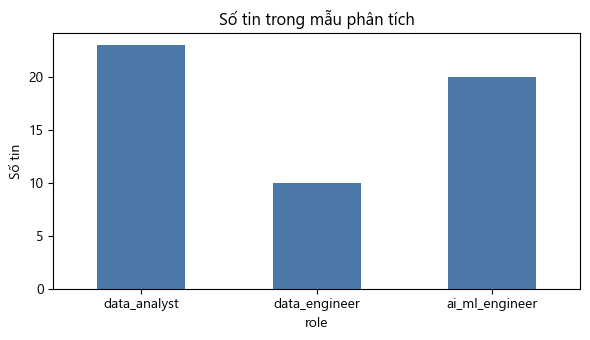

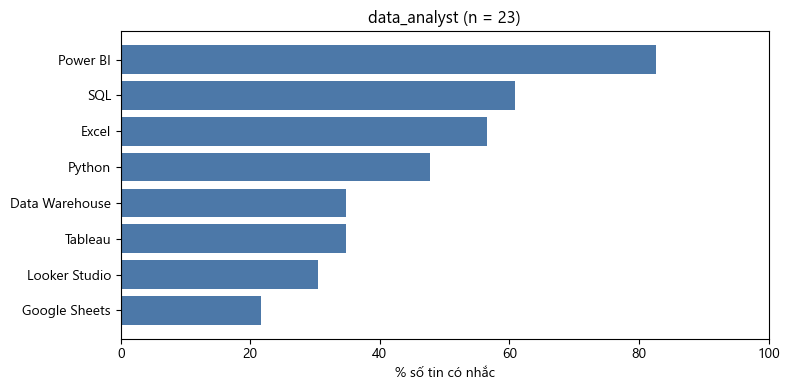

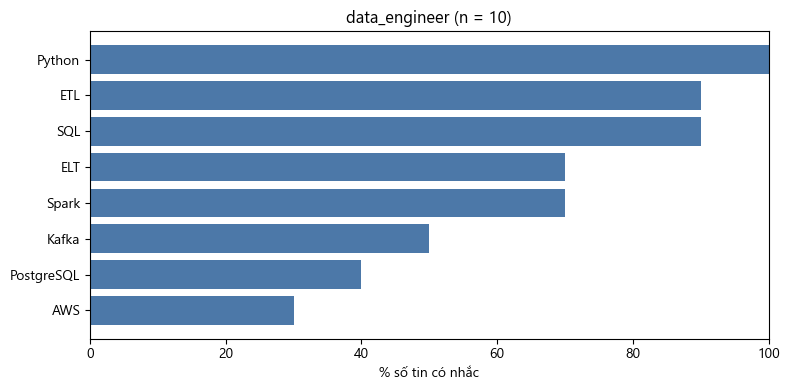

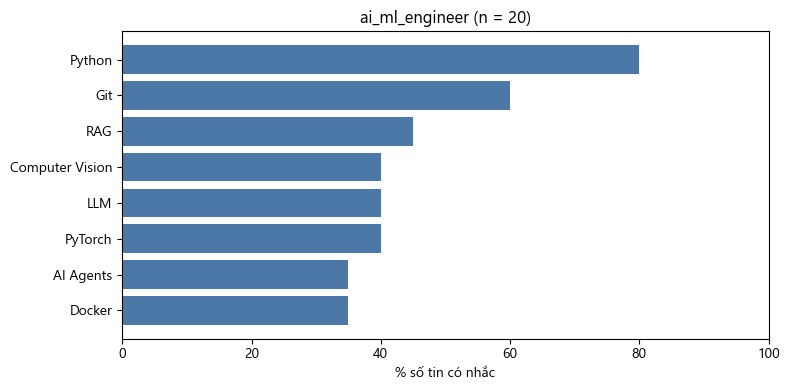

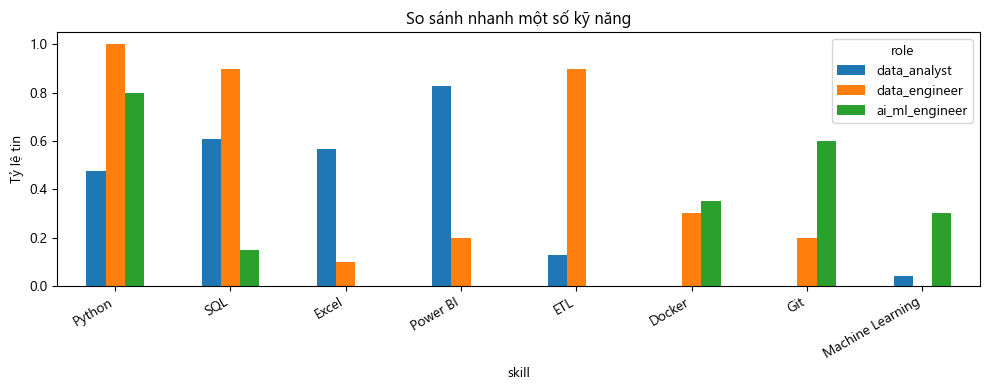

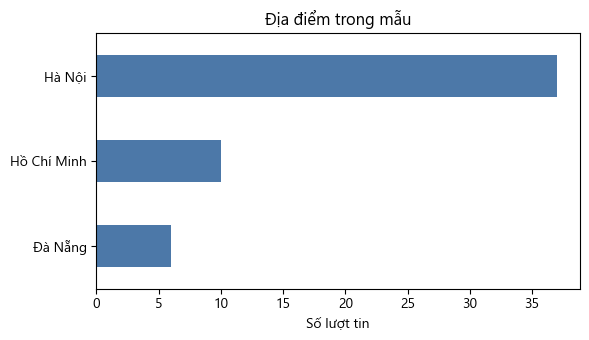

Hà Nội         37
Hồ Chí Minh    10
Đà Nẵng         6
Name: count, dtype: int64


In [5]:
role_order = ["data_analyst", "data_engineer", "ai_ml_engineer"]

plt.figure(figsize=(6, 3.5))
jobs_per_role.reindex(role_order).plot(kind="bar", color="#4C78A8")
plt.title("Số tin trong mẫu phân tích")
plt.ylabel("Số tin")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "chart_roles.png", dpi=120)
plt.show()

for role_name in role_order:
    top_skills = skill_frequency[skill_frequency["role"] == role_name].head(8).iloc[::-1]
    plt.figure(figsize=(8, 4))
    plt.barh(top_skills["skill"], top_skills["mention_rate"] * 100, color="#4C78A8")
    plt.xlabel("% số tin có nhắc")
    plt.title(f"{role_name} (n = {int(jobs_per_role[role_name])})")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.savefig(output_dir / f"chart_{role_name}.png", dpi=120)
    plt.show()

compare_skills = ["Python", "SQL", "Excel", "Power BI", "ETL", "Docker", "Git", "Machine Learning"]
comparison = (
    skill_frequency[skill_frequency["skill"].isin(compare_skills)]
    .pivot(index="skill", columns="role", values="mention_rate")
    .reindex(index=compare_skills, columns=role_order)
    .fillna(0)
)
comparison.plot(kind="bar", figsize=(10, 4))
plt.ylabel("Tỷ lệ tin")
plt.title("So sánh nhanh một số kỹ năng")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(output_dir / "chart_comparison.png", dpi=120)
plt.show()

# 1 tin nhiều nơi thì đếm nhiều lần
location_hits = []
city_keywords = {
    "Hà Nội": ["hà nội"],
    "Hồ Chí Minh": ["hồ chí minh", "hcm"],
    "Đà Nẵng": ["đà nẵng"],
}
for text in filtered_jobs["location_raw"]:
    lowered = text.lower()
    matched_city = False
    for city_name, keywords in city_keywords.items():
        if any(keyword in lowered for keyword in keywords):
            location_hits.append(city_name)
            matched_city = True
    if not matched_city:
        location_hits.append("Khác")

location_counts = pd.Series(location_hits).value_counts()
plt.figure(figsize=(6, 3.5))
location_counts.sort_values().plot(kind="barh", color="#4C78A8")
plt.title("Địa điểm trong mẫu")
plt.xlabel("Số lượt tin")
plt.tight_layout()
plt.savefig(output_dir / "chart_locations.png", dpi=120)
plt.show()
print(location_counts)

## 5. Thử skill gap và lưu file

Sửa `owned_skills` và `target_role` rồi chạy lại ô này. Đây chỉ là kỹ năng có trong tin nhưng chưa nằm trong danh sách mình khai, không phải kết luận năng lực.

In [6]:
owned_skills = ["Python", "SQL", "Excel"]
target_role = "data_analyst"

skill_gap = skill_frequency[
    (skill_frequency["role"] == target_role) & (~skill_frequency["skill"].isin(owned_skills))
].head(10)
print(f"Đang có: {owned_skills}")
print(f"Muốn xem nghề: {target_role} ({int(jobs_per_role[target_role])} tin)")
print(skill_gap.to_string(index=False))

filtered_jobs[
    ["source_job_id", "title", "company_raw", "location_raw", "experience_raw", "years", "role"]
].to_csv(output_dir / "filtered_jobs.csv", index=False, encoding="utf-8-sig")
job_skills.to_csv(output_dir / "job_skills.csv", index=False, encoding="utf-8-sig")
skill_frequency.to_csv(output_dir / "skill_frequency.csv", index=False, encoding="utf-8-sig")
print("Đã lưu vào", output_dir.resolve())
conn.close()

Đang có: ['Python', 'SQL', 'Excel']
Muốn xem nghề: data_analyst (23 tin)
        role          skill  job_count  role_job_count  mention_rate
data_analyst       Power BI         19              23         0.826
data_analyst Data Warehouse          8              23         0.348
data_analyst        Tableau          8              23         0.348
data_analyst  Looker Studio          7              23         0.304
data_analyst  Google Sheets          5              23         0.217
data_analyst              R          5              23         0.217
data_analyst       BigQuery          4              23         0.174
data_analyst            ETL          3              23         0.130
data_analyst        Airflow          2              23         0.087
data_analyst          MySQL          2              23         0.087
Đã lưu vào E:\ADY\outputs


## Ghi chú khi viết báo cáo

- Chỉ là một lát cắt TopCV ngày 11/10/2026. Mô tả là cụm từ đã trích, từ điển từ khóa có thể sót hoặc nhận nhầm.
- Mẫu số là số tin của từng nghề sau bước lọc, không phải toàn bộ tin trong bảng `jobs`.
- Tỷ lệ là tỷ lệ tin có nhắc kỹ năng. Không suy ra xác suất được tuyển.
- Chưa gán nhãn tay nên mình không báo accuracy của bước tách kỹ năng.